In [0]:

catalog = "databricks_rr"
schema = "default"
volume = "capstone"
BASE_PATH = f"/Volumes/{catalog}/{schema}/{volume}/training_files"

spark.sql(f"USE CATALOG {catalog}")
spark.sql(f"USE SCHEMA {schema}")

print(f"Catalog & Schema set to: {catalog}.{schema}")
print(f"Source Files Volume Path: {base_path}")


Catalog & Schema set to: databricks_rr.default
Source Files Volume Path: /Volumes/databricks_rr/default/capstone/training_files


In [0]:

display(dbutils.fs.ls(BASE_PATH))


path,name,size,modificationTime
dbfs:/Volumes/databricks_rr/default/capstone/training_files/attraction_maintenance.csv,attraction_maintenance.csv,1324,1795155997000
dbfs:/Volumes/databricks_rr/default/capstone/training_files/attractions.json,attractions.json,2562,1795155997000
dbfs:/Volumes/databricks_rr/default/capstone/training_files/park_entries.csv,park_entries.csv,8592,1795155997000
dbfs:/Volumes/databricks_rr/default/capstone/training_files/park_entries_incremental.csv,park_entries_incremental.csv,911,1795155997000
dbfs:/Volumes/databricks_rr/default/capstone/training_files/park_entry_changes.csv,park_entry_changes.csv,823,1795155997000


In [0]:
df_entries = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "true")
    .load(f"{BASE_PATH}/park_entries.csv")
)
df_entries.write.format("delta").mode("overwrite").saveAsTable("tp_entries_raw")

df_attractions = (
    spark.read.format("json")
    .option("multiline", "true")
    .load(f"{BASE_PATH}/attractions.json")
)
df_attractions.write.format("delta").mode("overwrite").saveAsTable("tp_attractions")

df_maint = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "true")
    .load(f"{BASE_PATH}/attraction_maintenance.csv")
)
df_maint.write.format("delta").mode("overwrite").saveAsTable("tp_maintenance")

df_changes = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "true")
    .load(f"{BASE_PATH}/park_entry_changes.csv")
)
df_changes.write.format("delta").mode("overwrite").saveAsTable("tp_entry_changes")

print("All 4 Delta tables created successfully.")


All 4 Delta tables created successfully.


## Section A: Data Ingestion and Exploration


In [0]:
# 01. Load the supplied CSV and JSON datasets using the setup notebook. Display each table and verify its row count.
for name in ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]:
    df = spark.table(name)
    display(df)
    print(name, df.count())


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,2026-11-20T17:20:00.000Z,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,2026-11-20T16:50:00.000Z,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,2026-11-20T10:30:00.000Z,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,2026-11-20T14:50:00.000Z,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,2026-11-20T13:40:00.000Z,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,2026-11-20T16:00:00.000Z,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,600.0,Cancelled,Kiosk


tp_entries_raw 121


attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


tp_attractions 10


maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


tp_maintenance 28


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,2026-11-20T16:20:00.000Z,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,2026-11-20T11:20:00.000Z,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,2026-11-20T11:00:00.000Z,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,2026-11-20T12:00:00.000Z,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,2026-11-20T13:00:00.000Z,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,2026-11-20T14:00:00.000Z,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,2026-11-20T15:00:00.000Z,35,16,Standard,350.0,Completed,Web


tp_entry_changes 10


In [0]:
# 02. Inspect the schema of tp_entries_raw. Identify string, integer, and decimal columns.
entries_df = spark.table("tp_entries_raw")
entries_df.printSchema()
for col_name, col_type in entries_df.dtypes:
    print(f"Column: {col_name:20} -> Type: {col_type}")


root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: date (nullable = true)
 |-- entry_time: timestamp (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

Column: entry_id             -> Type: int
Column: visitor_id           -> Type: string
Column: attraction_id        -> Type: string
Column: visit_date           -> Type: date
Column: entry_time           -> Type: timestamp
Column: wait_minutes         -> Type: int
Column: ride_minutes         -> Type: int
Column: ticket_type          -> Type: string
Column: ticket_price         -> Type: double
Column: status               -> Type: string
Column: booking_channel      -> Type: string


In [0]:
# 03. Select entry_id, attraction_id, visit_date, ticket_type, and ticket_price. Display the first 20 rows.
display(
    spark.table("tp_entries_raw")
    .select("entry_id", "attraction_id", "visit_date", "ticket_type", "ticket_price")
    .limit(20)
)


entry_id,attraction_id,visit_date,ticket_type,ticket_price
1001,A08,2026-10-06,Standard,350.0
1002,A01,2026-10-10,Standard,350.0
1003,A04,2026-10-11,Standard,350.0
1004,A05,2026-10-15,Express,650.0
1005,A07,2026-10-07,Standard,350.0
1006,A08,2026-10-09,VIP,900.0
1007,A08,2026-10-14,Standard,350.0
1008,A06,2026-10-01,Express,650.0
1009,A02,2026-10-16,Standard,350.0
1010,A02,2026-10-09,Express,600.0


In [0]:
# 04. Using SQL, find Completed entries where ticket_price is greater than 500.
display(spark.sql("""
SELECT *
FROM tp_entries_raw
WHERE status = 'Completed' AND ticket_price > 500
"""))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,2026-11-20T10:30:00.000Z,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,2026-11-20T13:40:00.000Z,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,2026-11-20T14:10:00.000Z,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,2026-11-20T13:10:00.000Z,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,2026-11-20T13:00:00.000Z,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,2026-11-20T17:20:00.000Z,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,2026-11-20T17:30:00.000Z,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,2026-11-20T14:20:00.000Z,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,2026-11-20T13:20:00.000Z,75,12,Express,600.0,Completed,App


In [0]:
# 05. Use DISTINCT and IN to examine ticket types and booking channels.
display(spark.sql("""
SELECT DISTINCT ticket_type, booking_channel
FROM tp_entries_raw
WHERE ticket_type IN ('Standard', 'Express', 'VIP')
  AND booking_channel IN ('Web', 'App', 'Kiosk', 'Partner')
ORDER BY ticket_type, booking_channel
"""))


ticket_type,booking_channel
Express,App
Express,Kiosk
Express,Partner
Express,Web
Standard,App
Standard,Kiosk
Standard,Partner
Standard,Web
VIP,App
VIP,Partner


In [0]:
# 06. Convert visit_date to a date type and count entries by visit date.
display(spark.sql("""
SELECT to_date(visit_date) AS visit_date, COUNT(*) AS entry_count
FROM tp_entries_raw
GROUP BY to_date(visit_date)
ORDER BY visit_date
"""))


visit_date,entry_count
2026-10-01,11
2026-10-02,4
2026-10-03,13
2026-10-04,7
2026-10-05,4
2026-10-06,6
2026-10-07,8
2026-10-08,7
2026-10-09,10
2026-10-10,7


## Section B: Cleaning and Transforming with PySpark


In [0]:
# 07. Find records with missing ticket_price or booking_channel values.
from pyspark.sql import functions as F

entries_df = spark.table("tp_entries_raw")
missing_df = entries_df.filter(F.col("ticket_price").isNull() | F.col("booking_channel").isNull())
display(missing_df)
print("Count of missing records:", missing_df.count())


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,2026-11-20T16:00:00.000Z,10,8,Standard,350.0,Completed,null
1016,V563,A10,2026-10-08,2026-11-20T15:10:00.000Z,30,10,Standard,null,Completed,Kiosk
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,400.0,Completed,null
1071,V553,A07,2026-10-03,2026-11-20T11:10:00.000Z,5,20,Standard,null,Completed,Partner
1087,V537,A01,2026-10-11,2026-11-20T10:00:00.000Z,75,4,Standard,350.0,Completed,null


Count of missing records: 5


In [0]:
# 08. Fill missing booking_channel values with Unknown in a new DataFrame; do not change the raw source.
filled_df = entries_df.fillna({"booking_channel": "Unknown"})
display(filled_df.filter(F.col("booking_channel") == "Unknown"))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,2026-11-20T16:00:00.000Z,10,8,Standard,350.0,Completed,Unknown
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,400.0,Completed,Unknown
1087,V537,A01,2026-10-11,2026-11-20T10:00:00.000Z,75,4,Standard,350.0,Completed,Unknown


In [0]:
# 09. Identify records with negative wait_minutes, zero ride_minutes, or nonpositive ticket_price.
invalid_df = entries_df.filter(
    (F.col("wait_minutes") < 0) | (F.col("ride_minutes") == 0) | (F.col("ticket_price") <= 0)
)
display(invalid_df)


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1021,V527,A03,2026-10-02,2026-11-20T13:00:00.000Z,-8,8,Express,650.0,Completed,Web
1036,V527,A06,2026-10-04,2026-11-20T14:40:00.000Z,40,0,Standard,400.0,Completed,Kiosk
1058,V516,A02,2026-10-08,2026-11-20T19:10:00.000Z,30,4,Standard,0.0,Completed,App
1073,V501,A03,2026-10-07,2026-11-20T18:50:00.000Z,-3,6,Express,650.0,Completed,App


In [0]:
# 10. Find duplicate entry_id values and create a deduplicated DataFrame.
dup_counts = entries_df.groupBy("entry_id").count().filter(F.col("count") > 1)
display(dup_counts)

dedup_df = entries_df.dropDuplicates(["entry_id"])
print(f"Raw count: {entries_df.count()}, Deduplicated count: {dedup_df.count()}")
dedup_df.createOrReplaceTempView("entries_dedup")


entry_id,count
1032,2


Raw count: 121, Deduplicated count: 120


In [0]:
# 11. Identify entry records whose attraction_id is missing from the attraction master.
attractions_df = spark.table("tp_attractions")
unmatched_df = dedup_df.join(attractions_df, on="attraction_id", how="left_anti")
display(unmatched_df)


attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A99,1092,V566,2026-10-03,2026-11-20T15:40:00.000Z,75,20,Standard,400.0,Completed,Kiosk


In [0]:
# 12. Create wait_category: Short (0-20), Medium (21-45), Long (above 45). Exclude invalid waits.
wait_df = (
    dedup_df
    .filter(F.col("wait_minutes") >= 0)
    .withColumn(
        "wait_category",
        F.when(F.col("wait_minutes") <= 20, "Short")
         .when(F.col("wait_minutes") <= 45, "Medium")
         .otherwise("Long")
    )
)
display(wait_df)
display(wait_df.groupBy("wait_category").count())


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,wait_category
1001,V515,A08,2026-10-06,2026-11-20T17:20:00.000Z,15,20,Standard,350.0,Cancelled,App,Short
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App,Long
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,350.0,Completed,Web,Medium
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web,Short
1005,V537,A07,2026-10-07,2026-11-20T16:50:00.000Z,5,6,Standard,350.0,Completed,Kiosk,Short
1006,V549,A08,2026-10-09,2026-11-20T10:30:00.000Z,10,8,VIP,900.0,Completed,Web,Short
1007,V529,A08,2026-10-14,2026-11-20T14:50:00.000Z,5,20,Standard,350.0,Completed,Web,Short
1008,V521,A06,2026-10-01,2026-11-20T13:40:00.000Z,40,6,Express,650.0,Completed,Kiosk,Medium
1009,V510,A02,2026-10-16,2026-11-20T16:00:00.000Z,10,8,Standard,350.0,Completed,null,Short
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,600.0,Cancelled,Kiosk,Short


wait_category,count
Short,56
Long,31
Medium,31


In [0]:
# 13. Join entries with attractions and extract location.zone and features from the nested JSON data.
joined_df = (
    dedup_df
    .join(attractions_df, on="attraction_id", how="left")
    .select(
        "entry_id",
        "attraction_id",
        "attraction_name",
        F.col("location.zone").alias("zone"),
        F.col("location.section").alias("section"),
        "features"
    )
)
display(joined_df)


entry_id,attraction_id,attraction_name,zone,section,features
1003,A04,Moonlight Train,West,W3,"List(Scenic, Family Friendly)"
1021,A03,Jungle Rapids,South,S1,"List(Water Ride, Outdoor)"
1030,A10,Mini Explorers,East,E3,"List(Kids, Indoor)"
1044,A04,Moonlight Train,West,W3,"List(Scenic, Family Friendly)"
1088,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"
1092,A99,null,null,null,null
1108,A03,Jungle Rapids,South,S1,"List(Water Ride, Outdoor)"
1015,A05,Meteor Drop,North,N2,"List(High Speed, Outdoor)"
1022,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"
1025,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"


## Section C: SQL Joins and Aggregations


In [0]:
# 14. Find Completed entries for Standard or Express tickets using WHERE, IN, AND, and BETWEEN.
display(spark.sql("""
SELECT *
FROM entries_dedup
WHERE status = 'Completed'
  AND ticket_type IN ('Standard', 'Express')
  AND ticket_price BETWEEN 300 AND 700
"""))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,2026-11-20T16:50:00.000Z,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,2026-11-20T14:50:00.000Z,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,2026-11-20T13:40:00.000Z,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,2026-11-20T16:00:00.000Z,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,2026-11-20T10:20:00.000Z,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,2026-11-20T13:40:00.000Z,10,15,Standard,400.0,Completed,Kiosk
1017,V501,A10,2026-10-06,2026-11-20T17:50:00.000Z,40,8,Standard,350.0,Completed,Partner


In [0]:
# 15. Calculate total valid ticket revenue and completed-entry counts by attraction.
display(spark.sql("""
SELECT e.attraction_id,
       a.attraction_name,
       ROUND(SUM(CASE WHEN e.ticket_price > 0 THEN e.ticket_price END), 2) AS valid_revenue,
       COUNT(*) AS completed_entries
FROM entries_dedup e
LEFT JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
GROUP BY e.attraction_id, a.attraction_name
ORDER BY e.attraction_id
"""))


attraction_id,attraction_name,valid_revenue,completed_entries
A01,Sky Spinner,4200.0,9
A02,Coral Carousel,2000.0,6
A03,Jungle Rapids,4500.0,8
A04,Moonlight Train,4850.0,11
A05,Meteor Drop,5850.0,10
A06,Pirate Voyage,4600.0,9
A07,Crystal Maze,4750.0,10
A08,Forest Flyers,3600.0,8
A09,Galaxy Theater,3200.0,7
A10,Mini Explorers,6050.0,14


In [0]:
# 16. Calculate average waiting time by attraction category, excluding invalid waits.
display(spark.sql("""
SELECT a.category,
       ROUND(AVG(e.wait_minutes), 2) AS avg_wait_minutes
FROM entries_dedup e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.wait_minutes >= 0
GROUP BY a.category
ORDER BY avg_wait_minutes DESC
"""))


category,avg_wait_minutes
Show,35.91
Adventure,33.96
Family,32.13
Thrill,30.5
Water,25.23


In [0]:
# 17. Join maintenance records with attractions and calculate completed-maintenance downtime by attraction.
display(spark.sql("""
SELECT a.attraction_id,
       a.attraction_name,
       COUNT(m.maintenance_id) AS completed_jobs,
       COALESCE(SUM(m.downtime_minutes), 0) AS total_downtime_minutes
FROM tp_attractions a
LEFT JOIN tp_maintenance m
  ON a.attraction_id = m.attraction_id AND m.maintenance_status = 'Completed'
GROUP BY a.attraction_id, a.attraction_name
ORDER BY a.attraction_id
"""))


attraction_id,attraction_name,completed_jobs,total_downtime_minutes
A01,Sky Spinner,1,120
A02,Coral Carousel,2,240
A03,Jungle Rapids,1,30
A04,Moonlight Train,2,75
A05,Meteor Drop,0,0
A06,Pirate Voyage,3,135
A07,Crystal Maze,1,120
A08,Forest Flyers,1,60
A09,Galaxy Theater,1,0
A10,Mini Explorers,1,120


In [0]:
# 18. Calculate total completed-entry revenue by park zone using the nested location.zone attribute.
display(spark.sql("""
SELECT COALESCE(a.location.zone, 'Unmatched') AS zone,
       ROUND(SUM(e.ticket_price), 2) AS completed_revenue
FROM entries_dedup e
LEFT JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed' AND e.ticket_price > 0
GROUP BY COALESCE(a.location.zone, 'Unmatched')
ORDER BY zone
"""))


zone,completed_revenue
East,12650.0
North,13250.0
South,9250.0
Unmatched,400.0
West,8450.0


## Section D: Delta Table Creation and CRUD


In [0]:
# 19. Create a clean managed Delta table named tp_entries_work using CTAS or a PySpark DataFrame write.
spark.sql("""
CREATE OR REPLACE TABLE tp_entries_work
USING DELTA
AS
SELECT DISTINCT
       entry_id, visitor_id, attraction_id, visit_date, entry_time,
       wait_minutes, ride_minutes, ticket_type, ticket_price, status,
       COALESCE(booking_channel, 'Unknown') AS booking_channel
FROM tp_entries_raw
WHERE wait_minutes >= 0 AND ride_minutes > 0 AND ticket_price > 0
""")

display(spark.sql("SELECT COUNT(*) AS total_rows FROM tp_entries_work"))


total_rows
114


In [0]:
# 20. Create a second Delta table from a PySpark DataFrame using saveAsTable().
completed_df = spark.table("tp_entries_work").filter(F.col("status") == "Completed")
completed_df.write.format("delta").mode("overwrite").saveAsTable("tp_completed_entries")

display(spark.table("tp_completed_entries"))
display(spark.sql("DESCRIBE DETAIL tp_completed_entries").select("name", "format", "numFiles"))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,400.0,Completed,Unknown
1099,V552,A05,2026-10-12,2026-11-20T16:40:00.000Z,40,12,VIP,950.0,Completed,Web
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App
1014,V564,A07,2026-10-01,2026-11-20T14:10:00.000Z,65,4,VIP,900.0,Completed,Partner
1049,V569,A10,2026-10-04,2026-11-20T13:00:00.000Z,40,6,Standard,350.0,Completed,Web
1081,V519,A02,2026-10-01,2026-11-20T19:30:00.000Z,40,12,Standard,350.0,Completed,Kiosk
1018,V535,A10,2026-10-01,2026-11-20T13:10:00.000Z,65,8,Express,600.0,Completed,App
1054,V535,A04,2026-10-06,2026-11-20T19:20:00.000Z,5,8,Standard,350.0,Completed,Kiosk
1079,V555,A02,2026-10-13,2026-11-20T19:20:00.000Z,50,15,Express,600.0,Completed,Kiosk


name,format,numFiles
databricks_rr.default.tp_completed_entries,delta,1


In [0]:
# 21. Insert two new valid visitor entries into tp_entries_work using SQL.
spark.sql("""
INSERT INTO tp_entries_work VALUES
(1126, 'V710', 'A06', '2026-10-21', '10:30:00', 18, 9, 'Standard', 400.0, 'Completed', 'Web'),
(1127, 'V711', 'A09', '2026-10-21', '11:15:00', 22, 11, 'Express', 600.0, 'Pending', 'App')
""")

display(spark.sql("SELECT * FROM tp_entries_work WHERE entry_id IN (1126, 1127)"))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1126,V710,A06,2026-10-21,2026-11-20T10:30:00.000Z,18,9,Standard,400.0,Completed,Web
1127,V711,A09,2026-10-21,2026-11-20T11:15:00.000Z,22,11,Express,600.0,Pending,App


In [0]:
# 22. Update the status and ticket price of an existing entry in tp_entries_work.
spark.sql("""
UPDATE tp_entries_work
SET status = 'Completed', ticket_price = 400.0
WHERE entry_id = 1023
""")

display(spark.sql("SELECT entry_id, status, ticket_price FROM tp_entries_work WHERE entry_id = 1023"))


entry_id,status,ticket_price
1023,Completed,400.0


In [0]:
# 23. Delete a Cancelled entry from tp_entries_work and verify the result.
spark.sql("""
DELETE FROM tp_entries_work
WHERE entry_id = 1001 AND status = 'Cancelled'
""")

display(spark.sql("""
SELECT COUNT(*) AS total_rows,
       SUM(CASE WHEN entry_id = 1001 THEN 1 ELSE 0 END) AS entry_1001_rows
FROM tp_entries_work
"""))


total_rows,entry_1001_rows
115,0


In [0]:
# 24. Use DESCRIBE EXTENDED to identify the working table type and location; explain managed versus external storage.
display(
    spark.sql("DESCRIBE EXTENDED tp_entries_work")
    .filter("col_name IN ('Type', 'Location', 'Provider', 'Catalog', 'Database', 'Table')")
)
# Managed vs External Storage:
# Managed Table: Databricks manages data files and metadata. Dropping the table removes both.
# External Table: Governed over an explicit storage path. Dropping the table drops metadata, leaving data files intact.


col_name,data_type,comment
Catalog,databricks_rr,
Database,default,
Table,tp_entries_work,
Type,MANAGED,
Location,abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/6ae6fc13-70b7-4f94-b491-272c2b3f8c76,
Provider,delta,


## Section E: MERGE / UPSERT and SCD


In [0]:
# 25. Inspect tp_entry_changes and separate existing entry IDs from new IDs.
print("Existing entry IDs (Updates):")
display(spark.sql("""
SELECT c.*
FROM tp_entry_changes c
LEFT SEMI JOIN tp_entries_work w ON c.entry_id = w.entry_id
ORDER BY c.entry_id
"""))

print("New entry IDs (Inserts):")
display(spark.sql("""
SELECT c.*
FROM tp_entry_changes c
LEFT ANTI JOIN tp_entries_work w ON c.entry_id = w.entry_id
ORDER BY c.entry_id
"""))


Existing entry IDs (Updates):


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,2026-11-20T16:20:00.000Z,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,2026-11-20T11:20:00.000Z,75,4,Standard,500.0,Completed,App


New entry IDs (Inserts):


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1121,V700,A01,2026-10-20,2026-11-20T11:00:00.000Z,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,2026-11-20T12:00:00.000Z,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,2026-11-20T13:00:00.000Z,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,2026-11-20T14:00:00.000Z,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,2026-11-20T15:00:00.000Z,35,16,Standard,350.0,Completed,Web


In [0]:
# 26. Use SQL MERGE to update matching entries and insert new entries into tp_entries_work (SCD Type 1).
spark.sql("""
MERGE INTO tp_entries_work AS t
USING tp_entry_changes AS s
ON t.entry_id = s.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *
""")
print("SQL MERGE completed successfully.")


SQL MERGE completed successfully.


In [0]:
# 27. Verify which entry IDs were updated and which were inserted.
display(spark.sql("""
SELECT w.*,
       CASE WHEN c.entry_id IS NOT NULL THEN 'From Changes Dataset' ELSE 'Original' END AS change_flag
FROM tp_entries_work w
JOIN tp_entry_changes c ON w.entry_id = c.entry_id
ORDER BY w.entry_id
"""))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,change_flag
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,400.0,Completed,App,From Changes Dataset
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,675.0,Completed,App,From Changes Dataset
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,500.0,Completed,App,From Changes Dataset
1068,V531,A10,2026-10-15,2026-11-20T16:20:00.000Z,30,4,Express,725.0,Completed,App,From Changes Dataset
1095,V563,A07,2026-10-09,2026-11-20T11:20:00.000Z,75,4,Standard,500.0,Completed,App,From Changes Dataset
1121,V700,A01,2026-10-20,2026-11-20T11:00:00.000Z,15,8,Standard,350.0,Completed,Web,From Changes Dataset
1122,V701,A02,2026-10-20,2026-11-20T12:00:00.000Z,20,10,Express,600.0,Completed,Web,From Changes Dataset
1123,V702,A03,2026-10-20,2026-11-20T13:00:00.000Z,25,12,Standard,350.0,Completed,Web,From Changes Dataset
1124,V703,A04,2026-10-20,2026-11-20T14:00:00.000Z,30,14,Express,600.0,Completed,Web,From Changes Dataset
1125,V704,A05,2026-10-20,2026-11-20T15:00:00.000Z,35,16,Standard,350.0,Completed,Web,From Changes Dataset


In [0]:
# 28. Create a separate Delta table and perform the same MERGE using the PySpark DeltaTable API.
from delta.tables import DeltaTable

df_initial = spark.table("tp_entries_raw").filter("wait_minutes >= 0 AND ride_minutes > 0 AND ticket_price > 0")
df_initial.write.format("delta").mode("overwrite").saveAsTable("tp_entries_work_py")

delta_target = DeltaTable.forName(spark, "tp_entries_work_py")
source_df = spark.table("tp_entry_changes")

(
    delta_target.alias("t")
    .merge(source_df.alias("s"), "t.entry_id = s.entry_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()
)

print("PySpark DeltaTable MERGE completed successfully.")
display(spark.table("tp_entries_work_py").filter("entry_id IN (SELECT entry_id FROM tp_entry_changes)"))


PySpark DeltaTable MERGE completed successfully.


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,2026-11-20T11:00:00.000Z,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,2026-11-20T11:10:00.000Z,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,2026-11-20T16:20:00.000Z,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,2026-11-20T11:20:00.000Z,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,2026-11-20T11:00:00.000Z,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,2026-11-20T12:00:00.000Z,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,2026-11-20T13:00:00.000Z,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,2026-11-20T14:00:00.000Z,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,2026-11-20T15:00:00.000Z,35,16,Standard,350.0,Completed,Web


In [0]:
# 29. Create an attraction-capacity history table with valid_from, valid_to, and is_current columns.
spark.sql("""
CREATE OR REPLACE TABLE tp_attraction_capacity_history (
    attraction_id STRING,
    capacity INT,
    valid_from DATE,
    valid_to DATE,
    is_current BOOLEAN
) USING DELTA
""")

spark.sql("""
INSERT INTO tp_attraction_capacity_history VALUES
('A01', 140, DATE('2026-01-01'), NULL, true),
('A02', 200, DATE('2026-01-01'), NULL, true)
""")

display(spark.table("tp_attraction_capacity_history"))


attraction_id,capacity,valid_from,valid_to,is_current
A01,140,2026-01-01,null,true
A02,200,2026-01-01,null,true


In [0]:
# 30. Implement an SCD Type 2 change for one attraction capacity; query both its historical and current rows.
spark.sql("""
UPDATE tp_attraction_capacity_history
SET valid_to = DATE('2026-10-01'),
    is_current = false
WHERE attraction_id = 'A01' AND is_current = true
""")

spark.sql("""
INSERT INTO tp_attraction_capacity_history VALUES
('A01', 180, DATE('2026-10-02'), NULL, true)
""")

display(spark.sql("""
SELECT * 
FROM tp_attraction_capacity_history
WHERE attraction_id = 'A01'
ORDER BY valid_from
"""))


attraction_id,capacity,valid_from,valid_to,is_current
A01,140,2026-01-01,2026-10-01,false
A01,180,2026-10-02,null,true


## Section F: Delta Internals, Time Travel, and Optimization


In [0]:
# 31. Use DESCRIBE DETAIL and DESCRIBE HISTORY on tp_entries_work. Record the storage format and operations.
display(spark.sql("DESCRIBE DETAIL tp_entries_work"))
display(spark.sql("DESCRIBE HISTORY tp_entries_work"))


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,ee8b7705-c160-4647-9466-38dd3af6120f,databricks_rr.default.tp_entries_work,null,abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/6ae6fc13-70b7-4f94-b491-272c2b3f8c76,2026-11-20T06:30:24.756Z,2026-11-20T06:30:42.000Z,List(),List(),4,14796,"Map(delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 7, numDeletionVectors -> 1)",false


version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
14,2026-11-20T06:30:42.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(entry_id#59520 = entry_id#59531)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(2836916894499245),b12881e5-b184-4780-9040-d11b2f8d6331,1120-060536-90mv7k6n-v2n,13,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3602, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 2309, materializeSourceTimeMs -> 1, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 778, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1507)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
13,2026-11-20T06:30:36.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,DELETE,"Map(predicate -> [""((entry_id#58765 = 1001) AND (status#58774 = Cancelled))""])",null,List(2836916894499245),e04414bb-fc3f-4c55-9d05-e1993140ec92,1120-060536-90mv7k6n-v2n,12,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 1, numAddedChangeFiles -> 0, executionTimeMs -> 843, numDeletionVectorsUpdated -> 1, numDeletedRows -> 1, scanTimeMs -> 481, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 362)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
12,2026-11-20T06:30:33.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,UPDATE,"Map(predicate -> [""(entry_id#58017 = 1023)""])",null,List(2836916894499245),28db0854-8377-4571-b8c3-b8607c273a6b,1120-060536-90mv7k6n-v2n,11,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 2084, numDeletionVectorsUpdated -> 0, scanTimeMs -> 539, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 3092, rewriteTimeMs -> 1545)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
11,2026-11-20T06:30:30.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(2836916894499245),8e5d9e38-489e-4b93-87b8-4459234c7c32,1120-060536-90mv7k6n-v2n,10,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 2, numOutputBytes -> 3113)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
10,2026-11-20T06:30:25.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(2836916894499245),4f51747f-2e45-41ec-85e2-f9d36e3b66d9,1120-060536-90mv7k6n-v2n,9,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 5144, numDeletionVectorsRemoved -> 0, numOutputRows -> 114, numOutputBytes -> 4989)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
9,2026-11-20T06:15:17.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(2836916894499245),dc

In [0]:
# 32. Find the table version immediately before your MERGE and query it using VERSION AS OF.
history_df = spark.sql("DESCRIBE HISTORY tp_entries_work")
merge_version = history_df.filter("operation = 'MERGE'").select("version").first()[0]
pre_merge_version = merge_version - 1

print(f"MERGE Version: {merge_version}, Pre-merge Version: {pre_merge_version}")
display(spark.sql(f"SELECT * FROM tp_entries_work VERSION AS OF {pre_merge_version}"))


MERGE Version: 14, Pre-merge Version: 13


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1040,V514,A03,2026-10-01,2026-11-20T19:10:00.000Z,5,15,Standard,400.0,Completed,Unknown
1099,V552,A05,2026-10-12,2026-11-20T16:40:00.000Z,40,12,VIP,950.0,Completed,Web
1120,V528,A04,2026-10-11,2026-11-20T12:10:00.000Z,15,20,Standard,350.0,Pending,Partner
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App
1014,V564,A07,2026-10-01,2026-11-20T14:10:00.000Z,65,4,VIP,900.0,Completed,Partner
1049,V569,A10,2026-10-04,2026-11-20T13:00:00.000Z,40,6,Standard,350.0,Completed,Web
1081,V519,A02,2026-10-01,2026-11-20T19:30:00.000Z,40,12,Standard,350.0,Completed,Kiosk
1084,V525,A04,2026-10-09,2026-11-20T11:20:00.000Z,10,10,Express,600.0,Cancelled,App
1095,V563,A07,2026-10-09,2026-11-20T11:20:00.000Z,75,4,Standard,350.0,Pending,Partner


In [0]:
# 33. Compare one updated entry before and after the MERGE.
sample_id = spark.table("tp_entry_changes").first()["entry_id"]

display(spark.sql(f"""
SELECT 'Before MERGE' AS snapshot, entry_id, ticket_price, status, booking_channel
FROM tp_entries_work VERSION AS OF {pre_merge_version}
WHERE entry_id = {sample_id}

UNION ALL

SELECT 'After MERGE' AS snapshot, entry_id, ticket_price, status, booking_channel
FROM tp_entries_work
WHERE entry_id = {sample_id}
"""))


snapshot,entry_id,ticket_price,status,booking_channel
Before MERGE,1003,350.0,Completed,Web
After MERGE,1003,400.0,Completed,App


In [0]:
# 34. Run OPTIMIZE, then compare the file count before and after. Explain why small tables may not change.
display(spark.sql("OPTIMIZE tp_entries_work"))
# Small tables already fit within a single compact file partition, so compaction does not alter file counts.


path,metrics
abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/6ae6fc13-70b7-4f94-b491-272c2b3f8c76,"List(1, 4, List(5144, 5144, 5144.0, 1, 5144), List(3092, 4989, 3699.0, 4, 14796), 0, null, null, 0, 1, 4, 0, true, 0, 0, 1795156263528, 1795156265210, 8, 1, null, List(1, 7), null, 11, 11, 522, 0, null, null, 0)"


In [0]:
# 35. Run ZORDER BY (attraction_id) if your table is not liquid clustered, and inspect the history.
display(spark.sql("OPTIMIZE tp_entries_work ZORDER BY (attraction_id)"))
display(spark.sql("DESCRIBE HISTORY tp_entries_work").limit(2))


path,metrics
abfss://unity-catalog-storage@dbstoragezlyxulkftegym.dfs.core.windows.net/7405612949365532/__unitystorage/catalogs/f87c0996-e508-40b8-abc1-87f667f1161a/tables/6ae6fc13-70b7-4f94-b491-272c2b3f8c76,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 5144), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1795156266323, 1795156266836, 8, 0, null, List(0, 0), null, 11, 11, 0, 0, null, null, 0)"


version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
15,2026-11-20T06:31:05.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(2836916894499245),bde7059c-a260-43bb-a00f-8443dfb3364c,1120-060536-90mv7k6n-v2n,14,SnapshotIsolation,false,"Map(numRemovedFiles -> 4, numRemovedBytes -> 14796, p25FileSize -> 5144, numDeletionVectorsRemoved -> 1, minFileSize -> 5144, numAddedFiles -> 1, maxFileSize -> 5144, p75FileSize -> 5144, p50FileSize -> 5144, numAddedBytes -> 5144)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13
14,2026-11-20T06:30:42.000Z,141715606078810,azuser7411_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(entry_id#59520 = entry_id#59531)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(2836916894499245),b12881e5-b184-4780-9040-d11b2f8d6331,1120-060536-90mv7k6n-v2n,13,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3602, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 2309, materializeSourceTimeMs -> 1, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 778, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1507)",null,Databricks-Runtime/19.16.x-aarch64-photon-scala2.13


In [0]:
# 36. Explain VACUUM retention and perform a safe dry run if supported; do not delete historical files.
# VACUUM purges obsolete files beyond the retention threshold (default 7 days).
# DRY RUN safely checks eligible files without deleting them.
display(spark.sql("VACUUM tp_entries_work DRY RUN"))


path


## Section G: Views and Parquet


In [0]:
# 37. Create a permanent view of valid Completed entries joined with attraction names.
spark.sql("""
CREATE OR REPLACE VIEW v_completed_attraction_entries AS
SELECT 
    e.entry_id,
    e.visitor_id,
    e.attraction_id,
    a.attraction_name,
    e.visit_date,
    e.ticket_type,
    e.ticket_price,
    e.wait_minutes
FROM tp_entries_work e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
""")

display(spark.sql("SELECT * FROM v_completed_attraction_entries LIMIT 10"))


entry_id,visitor_id,attraction_id,attraction_name,visit_date,ticket_type,ticket_price,wait_minutes
1023,V543,A10,Mini Explorers,2026-10-03,Standard,400.0,20
1004,V517,A05,Meteor Drop,2026-10-15,Express,650.0,20
1099,V552,A05,Meteor Drop,2026-10-12,VIP,950.0,40
1002,V535,A01,Sky Spinner,2026-10-10,Standard,350.0,65
1014,V564,A07,Crystal Maze,2026-10-01,VIP,900.0,65
1049,V569,A10,Mini Explorers,2026-10-04,Standard,350.0,40
1081,V519,A02,Coral Carousel,2026-10-01,Standard,350.0,40
1018,V535,A10,Mini Explorers,2026-10-01,Express,600.0,65
1054,V535,A04,Moonlight Train,2026-10-06,Standard,350.0,5
1079,V555,A02,Coral Carousel,2026-10-13,Express,600.0,50


In [0]:
# 38. Create a temporary view of entries with wait_minutes greater than 45.
spark.sql("""
CREATE OR REPLACE TEMPORARY VIEW temp_v_long_waits AS
SELECT * 
FROM tp_entries_work
WHERE wait_minutes > 45
""")

display(spark.sql("SELECT * FROM temp_v_long_waits"))


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App
1014,V564,A07,2026-10-01,2026-11-20T14:10:00.000Z,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,2026-11-20T13:10:00.000Z,65,8,Express,600.0,Completed,App
1035,V511,A03,2026-10-10,2026-11-20T19:50:00.000Z,65,15,Express,650.0,Cancelled,Partner
1079,V555,A02,2026-10-13,2026-11-20T19:20:00.000Z,50,15,Express,600.0,Completed,Kiosk
1092,V566,A99,2026-10-03,2026-11-20T15:40:00.000Z,75,20,Standard,400.0,Completed,Kiosk
1098,V517,A04,2026-10-10,2026-11-20T17:00:00.000Z,50,4,Standard,350.0,Completed,App
1118,V540,A07,2026-10-14,2026-11-20T10:10:00.000Z,65,12,Standard,350.0,Completed,Kiosk
1024,V537,A06,2026-10-06,2026-11-20T17:30:00.000Z,50,8,Express,650.0,Completed,Web
1111,V565,A06,2026-10-01,2026-11-20T12:50:00.000Z,65,4,Express,650.0,Completed,App


In [0]:
# 40. Write a DataFrame to Parquet in an approved Volume or external location; read it back and inspect its schema.
parquet_path = f"{BASE_PATH}/entries_parquet_backup"

df_work = spark.table("tp_entries_work")
df_work.write.mode("overwrite").parquet(parquet_path)

df_parquet_in = spark.read.parquet(parquet_path)
df_parquet_in.printSchema()
display(df_parquet_in.limit(5))


root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: date (nullable = true)
 |-- entry_time: timestamp (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1023,V543,A10,2026-10-03,2026-11-20T18:50:00.000Z,20,8,Standard,400.0,Completed,Web
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1099,V552,A05,2026-10-12,2026-11-20T16:40:00.000Z,40,12,VIP,950.0,Completed,Web
1120,V528,A04,2026-10-11,2026-11-20T12:10:00.000Z,15,20,Standard,350.0,Pending,Partner
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App


In [0]:
# 41. Convert that Parquet data to a new Delta table by reading it and writing Delta; explain what the Delta transaction log adds.
parquet_path = f"{BASE_PATH}/entries_parquet_backup"

df_from_parquet = spark.read.parquet(parquet_path)
df_from_parquet.write.format("delta").mode("overwrite").saveAsTable("tp_entries_converted_delta")

display(spark.table("tp_entries_converted_delta").limit(5))
# Delta adds the `_delta_log/` transaction log, providing ACID transactions, Time Travel, schema enforcement, and MERGE support.


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1023,V543,A10,2026-10-03,2026-11-20T18:50:00.000Z,20,8,Standard,400.0,Completed,Web
1004,V517,A05,2026-10-15,2026-11-20T17:50:00.000Z,20,6,Express,650.0,Completed,Web
1099,V552,A05,2026-10-12,2026-11-20T16:40:00.000Z,40,12,VIP,950.0,Completed,Web
1120,V528,A04,2026-10-11,2026-11-20T12:10:00.000Z,15,20,Standard,350.0,Pending,Partner
1002,V535,A01,2026-10-10,2026-11-20T15:00:00.000Z,65,6,Standard,350.0,Completed,App


## Section H: Structured Streaming


In [0]:
# 42. Create a streaming DataFrame from Spark rate with five rows per second.
streaming_rate_df = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 5)
    .load()
)
print("Streaming rate DataFrame created.")


Streaming rate DataFrame created.


In [0]:
# 43. Create visitor_event_id and simulated_wait_minutes columns from the streaming value.
streaming_events_df = streaming_rate_df.select(
    F.concat(F.lit("EVT_"), F.col("value").cast("string")).alias("visitor_event_id"),
    ((F.col("value") % 60) + 5).alias("simulated_wait_minutes"),
    F.col("timestamp")
)
print("Columns added to stream.")


Columns added to stream.


## Section I: Lakeflow / Delta Live Tables (DLT) & Incremental Loading


In [0]:
# 46. Create a SQL Lakeflow pipeline with a Bronze streaming table reading append-only tp_entries_raw.
# Note: For Lakeflow/DLT UI pipeline execution, use tp_lakeflow_pipeline.sql file:
sql_lakeflow_code = """
CREATE OR REFRESH STREAMING TABLE bronze_entries
AS SELECT * FROM STREAM(tp_entries_raw);
"""
print("Lakeflow SQL Bronze definition ready.")


Lakeflow SQL Bronze definition ready.


In [0]:
# 47. Create a Silver streaming table that retains valid Completed entries and calculates ticket revenue.
# Note: For Lakeflow/DLT UI pipeline execution, use tp_lakeflow_pipeline.sql file:
sql_silver_code = """
CREATE OR REFRESH STREAMING TABLE silver_entries (
    CONSTRAINT valid_ticket_price EXPECT (ticket_price > 0) ON VIOLATION DROP ROW,
    CONSTRAINT valid_status EXPECT (status = 'Completed') ON VIOLATION DROP ROW
)
AS SELECT 
    entry_id, visitor_id, attraction_id, TO_DATE(visit_date) AS visit_date,
    ticket_type, ticket_price, COALESCE(booking_channel, 'Unknown') AS booking_channel,
    status, wait_minutes, ride_minutes
FROM STREAM(LIVE.bronze_entries);
"""
print("Lakeflow SQL Silver definition ready.")


Lakeflow SQL Silver definition ready.


In [0]:
# 48. Create a Gold materialized view showing entry counts and revenue by attraction; run and inspect the pipeline graph.
# Note: For Lakeflow/DLT UI pipeline execution, use tp_lakeflow_pipeline.sql file:
sql_gold_code = """
CREATE OR REFRESH MATERIALIZED VIEW gold_attraction_kpis
AS SELECT 
    attraction_id,
    COUNT(entry_id) AS completed_entries,
    ROUND(SUM(ticket_price), 2) AS total_revenue,
    ROUND(AVG(wait_minutes), 1) AS avg_wait_time
FROM LIVE.silver_entries
GROUP BY attraction_id;
"""
print("Lakeflow SQL Gold definition ready.")


Lakeflow SQL Gold definition ready.


In [0]:
# 49. Create a separate Python Lakeflow pipeline for the same Bronze-Silver-Gold flow using distinct output names.
py_dlt_pipeline_code = """
import dlt
from pyspark.sql.functions import col, to_date

@dlt.table(name="py_bronze_entries")
def py_bronze_entries():
    return spark.readStream.table("tp_entries_raw")

@dlt.table(name="py_silver_entries")
@dlt.expect_or_drop("valid_price", "ticket_price > 0")
@dlt.expect_or_drop("completed_only", "status = 'Completed'")
def py_silver_entries():
    return (
        dlt.read_stream("py_bronze_entries")
        .withColumn("visit_date", to_date(col("visit_date")))
        .fillna({"booking_channel": "Unknown"})
    )

@dlt.table(name="py_gold_attraction_kpis")
def py_gold_attraction_kpis():
    return (
        dlt.read("py_silver_entries")
        .groupBy("attraction_id")
        .agg({"entry_id": "count", "ticket_price": "sum", "wait_minutes": "avg"})
        .withColumnRenamed("count(entry_id)", "completed_entries")
        .withColumnRenamed("sum(ticket_price)", "total_revenue")
        .withColumnRenamed("avg(wait_minutes)", "avg_wait_time")
    )
"""
print("Python Lakeflow DLT pipeline ready.")


Python Lakeflow DLT pipeline ready.


In [0]:
# 50. Append park_entries_incremental.csv to tp_entries_raw only after the first pipeline run; rerun the pipeline and verify the Gold totals.
df_incremental = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "true")
    .load(f"{BASE_PATH}/park_entries_incremental.csv")
)

df_incremental.write.format("delta").mode("append").saveAsTable("tp_entries_raw")
print(f"Successfully appended {df_incremental.count()} rows to tp_entries_raw.")


Successfully appended 12 rows to tp_entries_raw.


## Final Capstone: Park Operations Dashboard


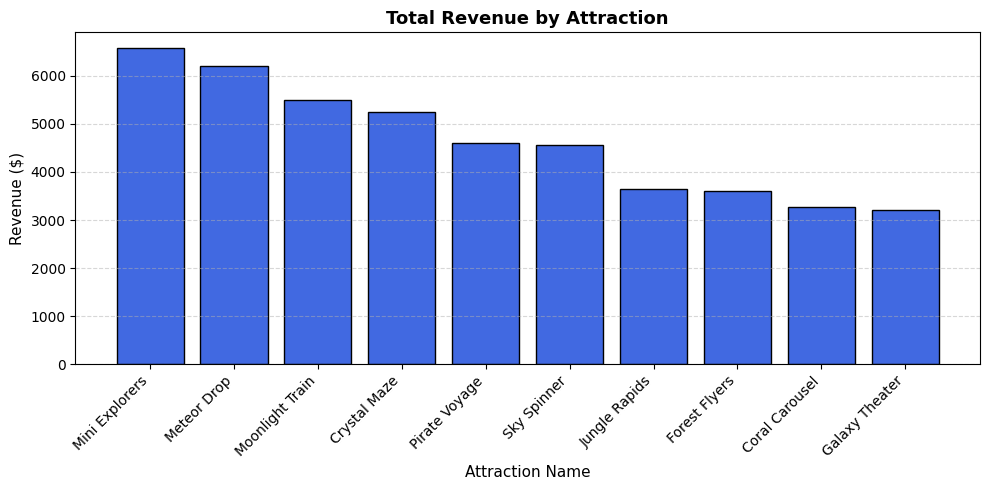

In [0]:
# Capstone Chart 1: Bar Chart - Total Revenue by Attraction
import matplotlib.pyplot as plt

df_rev = spark.sql("""
    SELECT a.attraction_name, ROUND(SUM(e.ticket_price), 2) AS total_revenue
    FROM tp_entries_work e
    JOIN tp_attractions a ON e.attraction_id = a.attraction_id
    WHERE e.status = 'Completed'
    GROUP BY a.attraction_name
    ORDER BY total_revenue DESC
""").toPandas()

plt.figure(figsize=(10, 5))
plt.bar(df_rev["attraction_name"], df_rev["total_revenue"], color="royalblue", edgecolor="black")
plt.title("Total Revenue by Attraction", fontsize=13, fontweight="bold")
plt.xlabel("Attraction Name", fontsize=11)
plt.ylabel("Revenue ($)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

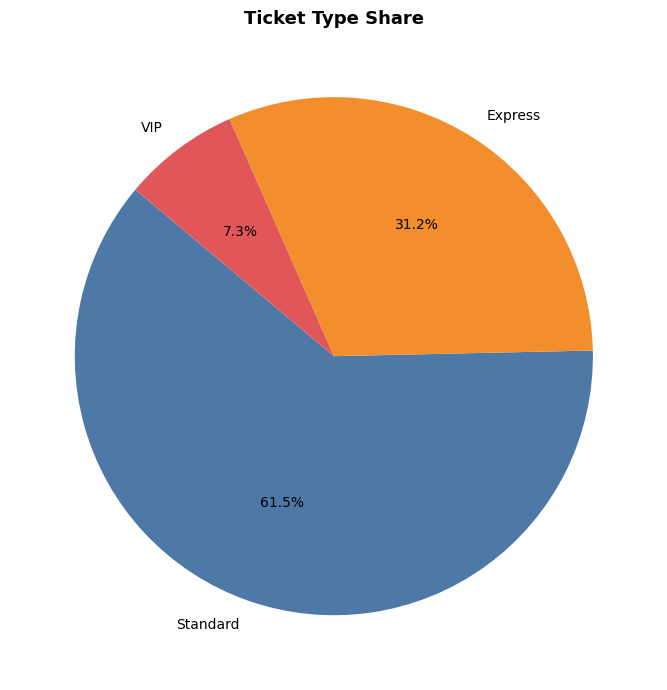

In [0]:
# Capstone Chart 2: Pie Chart - Ticket Type Share
import matplotlib.pyplot as plt

df_ticket = spark.sql("""
    SELECT ticket_type, COUNT(entry_id) AS total_entries
    FROM tp_entries_work
    WHERE status = 'Completed'
    GROUP BY ticket_type
""").toPandas()

plt.figure(figsize=(7, 7))
plt.pie(
    df_ticket["total_entries"],
    labels=df_ticket["ticket_type"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4e79a7", "#f28e2c", "#e15759"]
)
plt.title("Ticket Type Share", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

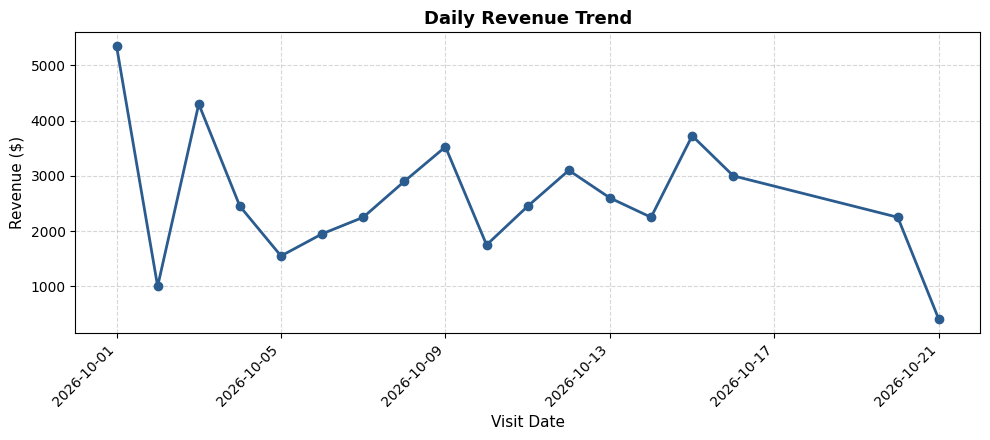

In [0]:
# Capstone Chart 3: Line Chart - Daily Revenue Trend
import matplotlib.pyplot as plt

df_daily = spark.sql("""
    SELECT TO_DATE(visit_date) AS visit_day, ROUND(SUM(ticket_price), 2) AS daily_revenue
    FROM tp_entries_work
    WHERE status = 'Completed'
    GROUP BY TO_DATE(visit_date)
    ORDER BY visit_day
""").toPandas()

plt.figure(figsize=(10, 4.5))
plt.plot(df_daily["visit_day"], df_daily["daily_revenue"], marker="o", color="#2b5c8f", linewidth=2)
plt.title("Daily Revenue Trend", fontsize=13, fontweight="bold")
plt.xlabel("Visit Date", fontsize=11)
plt.ylabel("Revenue ($)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

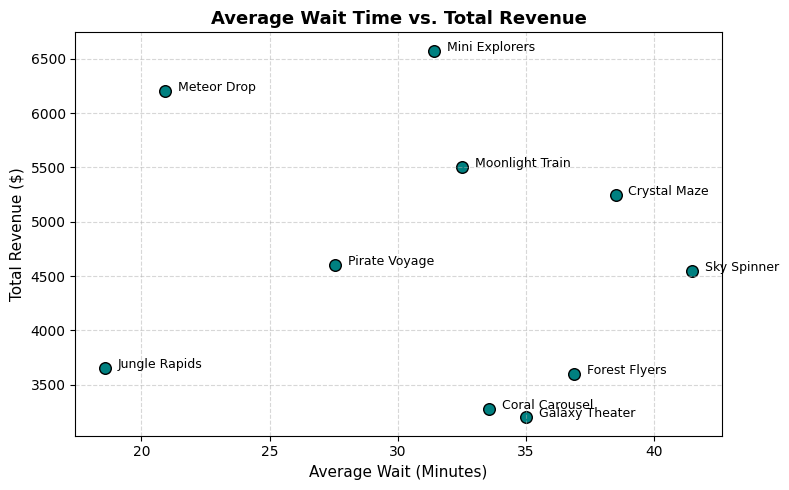

In [0]:
# Capstone Chart 4: Scatter Plot - Average Wait vs Total Revenue
import matplotlib.pyplot as plt

df_wait_rev = spark.sql("""
    SELECT a.attraction_name,
           ROUND(AVG(e.wait_minutes), 2) AS avg_wait,
           ROUND(SUM(e.ticket_price), 2) AS total_revenue
    FROM tp_entries_work e
    JOIN tp_attractions a ON e.attraction_id = a.attraction_id
    WHERE e.status = 'Completed'
    GROUP BY a.attraction_name
""").toPandas()

plt.figure(figsize=(8, 5))
plt.scatter(df_wait_rev["avg_wait"], df_wait_rev["total_revenue"], color="teal", s=70, edgecolors="k")
for _, row in df_wait_rev.iterrows():
    plt.annotate(row["attraction_name"], (row["avg_wait"] + 0.5, row["total_revenue"]), fontsize=9)

plt.title("Average Wait Time vs. Total Revenue", fontsize=13, fontweight="bold")
plt.xlabel("Average Wait (Minutes)", fontsize=11)
plt.ylabel("Total Revenue ($)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()